**by: [João Ataíde](https://www.joaoataide.com)**
# **CAP 09: Análise de Agrupamentos**

---



In [1]:
#importar bibliotecas
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats import chi2

from scipy.spatial.distance import pdist, squareform, cdist
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans
from sklearn.manifold import MDS

A análise de agrupamentos (ou `análise de clusters`, ou `análise de conglomerados`) é um conjunto de técnicas exploratórias para verificar se há comportamentos semelhantes entre observações (indivíduos, empresas, municípios, países ...) em relação a determinadas variáveis. O objetivo é alocar as observações em uma quantidade pequena de grupos `homogêneos internamente` e `heterogêneos entre si`.

* `Técnica exploratória (de interdependência):` não tem caráter preditivo. Se entrarem novas observações ou variáveis, a análise precisa ser refeita, e os grupos podem mudar completamente.
* `Sensível a outliers:` observações muito discrepantes podem fundir ou distorcer os grupos, por isso vale estudar os dados antes.

A lógica da análise é:

1. Definir os objetivos de pesquisa.
2. Escolher a medida de distância (variáveis métricas) ou de semelhança (variáveis binárias).
3. Escolher o esquema de aglomeração (hierárquico ou não hierárquico).
4. Analisar, interpretar e comparar os resultados.

`OBS:` *Não faz sentido atribuir pesos arbitrários a variáveis qualitativas (como escalas Likert) para depois agrupar. Para variáveis qualitativas existe a análise de correspondência (capítulo 11).*

Veja a ideia com um exemplo hipotético, como nas Figuras 9.2 a 9.5 do livro: um pesquisador quer propor programas sociais de saúde para grupos homogêneos de moradores de um município, com base na idade e na renda.

c:\Users\jv_at\anaconda3\envs\bmte\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


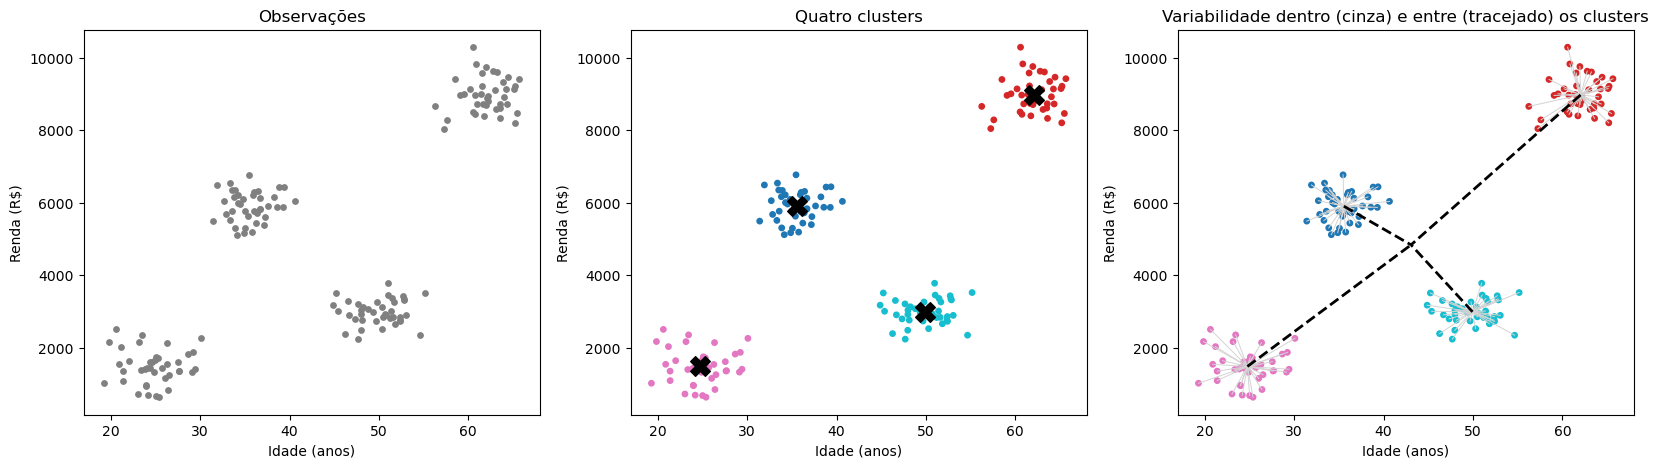

In [2]:
np.random.seed(7)

# Simulando quatro grupos de moradores (idade, renda)
centros = [(25, 1500), (35, 6000), (50, 3000), (62, 9000)]
moradores = pd.concat([pd.DataFrame({"idade": np.random.normal(cx, 2.5, 40),
                                     "renda": np.random.normal(cy, 450, 40)}) for cx, cy in centros],
                      ignore_index=True)

# Padronizando antes do k-means, já que idade (anos) e renda (R$) estão em unidades diferentes
kmeans_moradores = KMeans(n_clusters=4, n_init=10, random_state=42).fit((moradores - moradores.mean()) / moradores.std())
moradores["cluster"] = kmeans_moradores.labels_
centroides_moradores = moradores.groupby("cluster")[["idade", "renda"]].mean()
media_geral = moradores[["idade", "renda"]].mean()

fig, ax = plt.subplots(1, 3, figsize = (20, 5))

# Figura 9.2: observações
ax[0].scatter(moradores["idade"], moradores["renda"], color='gray', s=15)
ax[0].set_title('Observações')

# Figura 9.3: quatro clusters
ax[1].scatter(moradores["idade"], moradores["renda"], c=moradores["cluster"], cmap='tab10', s=15)
ax[1].scatter(centroides_moradores["idade"], centroides_moradores["renda"], marker='X', s=200, color='black')
ax[1].set_title('Quatro clusters')

# Figura 9.4: variabilidade dentro dos clusters e entre eles
for _, linha in moradores.iterrows():
    c = centroides_moradores.loc[linha["cluster"]]
    ax[2].plot([linha["idade"], c["idade"]], [linha["renda"], c["renda"]], color='lightgray', linewidth=0.7)
for _, c in centroides_moradores.iterrows():
    ax[2].plot([c["idade"], media_geral["idade"]], [c["renda"], media_geral["renda"]], 'k--', linewidth=2)
ax[2].scatter(moradores["idade"], moradores["renda"], c=moradores["cluster"], cmap='tab10', s=15)
ax[2].set_title('Variabilidade dentro (cinza) e entre (tracejado) os clusters')

for eixo in ax:
    eixo.set_xlabel('Idade (anos)')
    eixo.set_ylabel('Renda (R$)')

# Exibir o gráfico
plt.show()

No ano seguinte, um grupo de bilionários em idade avançada se muda para a cidade. Refazendo a análise com quatro clusters, os grupos anteriores deixam de existir (Figura 9.5):

c:\Users\jv_at\anaconda3\envs\bmte\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


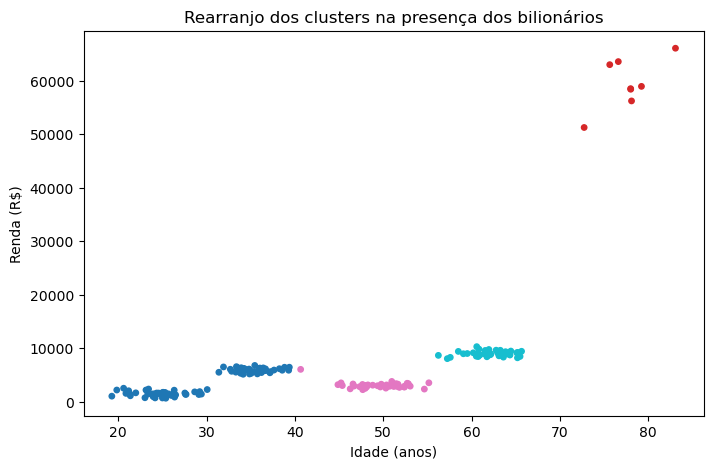

cluster
0    79
1     8
2    41
3    40
dtype: int64


In [3]:
np.random.seed(7)
bilionarios = pd.DataFrame({"idade": np.random.normal(78, 3, 8), "renda": np.random.normal(60000, 6000, 8)})
moradores_novos = pd.concat([moradores[["idade", "renda"]], bilionarios], ignore_index=True)

moradores_novos["cluster"] = KMeans(n_clusters=4, n_init=10, random_state=42).fit((moradores_novos - moradores_novos.mean()) / moradores_novos.std()).labels_

fig, ax = plt.subplots(figsize = (8, 5))
ax.scatter(moradores_novos["idade"], moradores_novos["renda"], c=moradores_novos["cluster"], cmap='tab10', s=15)
ax.set_xlabel('Idade (anos)')
ax.set_ylabel('Renda (R$)')
ax.set_title('Rearranjo dos clusters na presença dos bilionários')

# Exibir o gráfico
plt.show()

print(moradores_novos.groupby("cluster").size())

Note que os oito bilionários formam um grupo próprio e, para manter quatro clusters, dois dos grupos originais se fundem em um só, com 79 moradores. Por isso a análise de agrupamentos precisa ser refeita sempre que entram novas observações, e os outliers devem ser estudados antes.

## **Medidas de Distância e de Semelhança**

* `Medidas de distância (dissimilaridade):` usadas com variáveis métricas. Quanto maior a diferença entre os valores de duas observações, maior a distância e menor a similaridade.
* `Medidas de semelhança (similaridade):` usadas com variáveis binárias. Quanto mais respostas iguais (1-1 ou 0-0), maior a semelhança.

### **Medidas de distância para variáveis métricas**

Para duas observações $p$ e $q$ com $k$ variáveis métricas:

* `Euclidiana:` a mais usada, vem do teorema de Pitágoras. $d_{pq} = \sqrt{\sum_{j=1}^{k}(X_{jp} - X_{jq})^2}$
* `Quadrática euclidiana:` deixa os saltos de distância mais nítidos quando os valores são próximos. $d_{pq} = \sum_{j=1}^{k}(X_{jp} - X_{jq})^2$
* `Minkowski:` forma geral, com $m$ inteiro positivo. $d_{pq} = \left[\sum_{j=1}^{k}|X_{jp} - X_{jq}|^m\right]^{1/m}$
* `Manhattan (bloco):` caso $m = 1$. $d_{pq} = \sum_{j=1}^{k}|X_{jp} - X_{jq}|$
* `Chebychev (máxima):` caso $m = \infty$, considera apenas a maior diferença. $d_{pq} = máx|X_{jp} - X_{jq}|$
* `Canberra:` para variáveis só com valores positivos, varia de 0 a $k$. $d_{pq} = \sum_{j=1}^{k}\frac{|X_{jp} - X_{jq}|}{X_{jp} + X_{jq}}$

A `correlação de Pearson` entre duas linhas também pode ser usada, mas como medida de similaridade (varia de −1 a 1). É útil quando as observações são períodos de tempo e queremos agrupar períodos com comportamento parecido.

$\rho_{pq} = \frac{\sum_{j=1}^{k}(X_{jp} - \overline{X}_p)\cdot(X_{jq} - \overline{X}_q)}{\sqrt{\sum_{j=1}^{k}(X_{jp} - \overline{X}_p)^2}\cdot\sqrt{\sum_{j=1}^{k}(X_{jq} - \overline{X}_q)^2}}$

In [4]:
# Duas observações com três variáveis métricas
obs_1 = np.array([3.7, 2.7, 9.1])
obs_2 = np.array([7.8, 8.0, 1.5])

def medidas_distancia(p, q):

    resultado = {
        "Euclidiana": np.sqrt(np.sum((p - q)**2)),
        "Quadrática euclidiana": np.sum((p - q)**2),
        "Manhattan": np.sum(np.abs(p - q)),
        "Chebychev": np.max(np.abs(p - q)),
        "Canberra": np.sum(np.abs(p - q) / (p + q)),
        "Correlação de Pearson": np.corrcoef(p, q)[0, 1]
    }

    return pd.Series(resultado).round(3)

medidas_distancia(obs_1, obs_2)

Euclidiana                10.132
Quadrática euclidiana    102.660
Manhattan                 17.000
Chebychev                  7.600
Canberra                   1.569
Correlação de Pearson     -0.993
dtype: float64

Geometricamente (Figuras 9.6 a 9.8 do livro), a distância euclidiana vem do teorema de Pitágoras aplicado duas vezes: primeiro na projeção dos pontos sobre o plano $X_1 X_2$, $d'_{12} = \sqrt{(X_{11}-X_{12})^2 + (X_{21}-X_{22})^2}$, e depois no triângulo formado com a diferença vertical, $d_{12} = \sqrt{(d'_{12})^2 + (X_{31}-X_{32})^2}$.

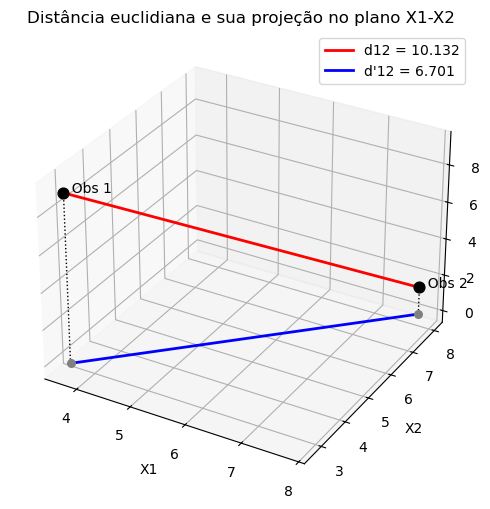

In [5]:
fig = plt.figure(figsize = (8, 6))
ax = fig.add_subplot(projection='3d')

# Pontos, projeções no plano X1-X2 e segmentos verticais
for ponto, nome in [(obs_1, "Obs 1"), (obs_2, "Obs 2")]:
    ax.scatter(*ponto, s=60, color='black')
    ax.scatter(ponto[0], ponto[1], 0, s=30, color='gray')
    ax.plot([ponto[0], ponto[0]], [ponto[1], ponto[1]], [0, ponto[2]], 'k:', linewidth=1)
    ax.text(*ponto, f'  {nome}')

# Distância euclidiana d12 e sua projeção d'12
ax.plot(*zip(obs_1, obs_2), color='red', linewidth=2, label=f'd12 = {np.round(np.sqrt(np.sum((obs_1 - obs_2)**2)), 3)}')
ax.plot([obs_1[0], obs_2[0]], [obs_1[1], obs_2[1]], [0, 0], color='blue', linewidth=2,
        label=f"d'12 = {np.round(np.sqrt(np.sum((obs_1[:2] - obs_2[:2])**2)), 3)}")

ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('X3')
ax.set_title('Distância euclidiana e sua projeção no plano X1-X2')
ax.legend()

# Exibir o gráfico
plt.show()

In [6]:
# Conferindo com o scipy
for metrica in ["euclidean", "sqeuclidean", "cityblock", "chebyshev", "canberra"]:
    print(f"{metrica}: {np.round(pdist([obs_1, obs_2], metric=metrica)[0], 3)}")

euclidean: 10.132
sqeuclidean: 102.66
cityblock: 17.0
chebyshev: 7.6
canberra: 1.569


Note que medidas diferentes geram resultados diferentes, o que pode levar a agrupamentos diferentes. Veja o que acontece com uma terceira observação:

In [7]:
tres_obs = pd.DataFrame([[3.7, 2.7, 9.1],
                         [7.8, 8.0, 1.5],
                         [8.9, 1.0, 2.7]],
                        index=["Obs 1", "Obs 2", "Obs 3"], columns=["X1", "X2", "X3"])

pares = ["1 e 2", "1 e 3", "2 e 3"]
pd.DataFrame({"Euclidiana": pdist(tres_obs, "euclidean"),
              "Chebychev": pdist(tres_obs, "chebyshev")}, index=pares).round(3)

,Euclidiana,Chebychev
1 e 2,10.132,7.6
1 e 3,8.420,6.4
2 e 3,7.187,7.0


Pela distância euclidiana as observações mais parecidas são a 2 e a 3 ($d_{23} = 7.187$), mas pela distância de Chebychev são a 1 e a 3 ($d_{13} = 6.4$). Por isso a escolha da medida precisa ser justificada pelos objetivos da pesquisa.

#### **Padronização (Zscores)**

Se as variáveis estiverem em unidades diferentes (renda em R$, idade em anos, número de filhos ...), as de maior magnitude dominam a distância. Nesse caso padronizamos cada variável:

$ZX_{ji} = \frac{X_{ji} - \overline{X}_j}{S_j}$

Toda variável padronizada fica com média 0 e desvio-padrão 1, sem mudar o formato da sua distribuição, e passa a contribuir igualmente para a distância.

In [8]:
# Exemplo com variáveis em unidades diferentes
clientes = pd.DataFrame({
    "Renda": [2500, 8000, 4200, 12000, 3100],
    "Idade": [23, 45, 31, 52, 28],
    "Filhos": [0, 2, 1, 3, 0]
})

clientes_padronizado = (clientes - clientes.mean()) / clientes.std()

print(clientes_padronizado.agg(["mean", "std"]).round(3))
clientes_padronizado.round(3)

      Renda  Idade  Filhos
mean   -0.0    0.0     0.0
std     1.0    1.0     1.0


,Renda,Idade,Filhos
0,-0.866,-1.050,-0.920
1,0.510,0.754,0.614
2,-0.440,-0.394,-0.153
3,1.511,1.328,1.381
4,-0.716,-0.640,-0.920


### **Medidas de semelhança para variáveis binárias**

Com variáveis binárias (presença = 1, ausência = 0), contamos os pares de respostas de duas observações $p$ e $q$:

| $p$ \ $q$ | 1 | 0 |
|---|---|---|
| **1** | a | b |
| **0** | c | d |

* `Emparelhamento simples:` a mais usada, dá o mesmo peso a 1-1 e 0-0. $s_{pq} = \frac{a+d}{a+b+c+d}$
* `Jaccard:` ignora os pares 0-0. $s_{pq} = \frac{a}{a+b+c}$
* `Dice:` dobra o peso dos pares 1-1. $s_{pq} = \frac{2a}{2a+b+c}$
* `AntiDice:` dobra o peso das divergências. $s_{pq} = \frac{a}{a+2\cdot(b+c)}$
* `Russell e Rao:` só considera os pares 1-1. $s_{pq} = \frac{a}{a+b+c+d}$
* `Ochiai:` $s_{pq} = \frac{a}{\sqrt{(a+b)\cdot(a+c)}}$
* `Yule:` varia de −1 a 1. $s_{pq} = \frac{a\cdot d - b\cdot c}{a\cdot d + b\cdot c}$
* `Rogers e Tanimoto:` dobra o peso das respostas discrepantes. $s_{pq} = \frac{a+d}{a+d+2\cdot(b+c)}$
* `Sneath e Sokal:` dobra o peso das respostas convergentes. $s_{pq} = \frac{2\cdot(a+d)}{2\cdot(a+d)+b+c}$
* `Hamann:` convergências menos divergências, varia de −1 a 1. $s_{pq} = \frac{(a+d)-(b+c)}{a+b+c+d}$

*Ex: ao agrupar pessoas, o fato de duas comerem lagosta todos os dias (1-1) é uma evidência de semelhança mais forte do que ambas não comerem (0-0). Medidas como Jaccard e Dice levam isso em conta.*

`OBS:` *Não faz sentido padronizar variáveis binárias.*

In [9]:
# Duas observações com sete variáveis binárias
binaria_1 = np.array([0, 0, 1, 1, 0, 1, 1])
binaria_2 = np.array([0, 1, 1, 1, 1, 0, 1])

def medidas_semelhanca(p, q):

    a = np.sum((p == 1) & (q == 1))
    b = np.sum((p == 1) & (q == 0))
    c = np.sum((p == 0) & (q == 1))
    d = np.sum((p == 0) & (q == 0))

    resultado = {
        "Emparelhamento simples": (a + d) / (a + b + c + d),
        "Jaccard": a / (a + b + c),
        "Dice": 2 * a / (2 * a + b + c),
        "AntiDice": a / (a + 2 * (b + c)),
        "Russell e Rao": a / (a + b + c + d),
        "Ochiai": a / np.sqrt((a + b) * (a + c)),
        "Yule": (a * d - b * c) / (a * d + b * c),
        "Rogers e Tanimoto": (a + d) / (a + d + 2 * (b + c)),
        "Sneath e Sokal": 2 * (a + d) / (2 * (a + d) + b + c),
        "Hamann": ((a + d) - (b + c)) / (a + b + c + d)
    }

    print(f"a = {a} | b = {b} | c = {c} | d = {d}")
    return pd.Series(resultado).round(3)

medidas_semelhanca(binaria_1, binaria_2)

a = 3 | b = 1 | c = 2 | d = 1


Emparelhamento simples    0.571
Jaccard                   0.500
Dice                      0.667
AntiDice                  0.333
Russell e Rao             0.429
Ochiai                    0.671
Yule                      0.200
Rogers e Tanimoto         0.400
Sneath e Sokal            0.727
Hamann                    0.143
dtype: float64

## **Esquemas de Aglomeração**

A escolha do esquema de aglomeração é tão importante quanto a escolha da medida de distância.

* `Hierárquicos:` formam os grupos passo a passo.
    * `Aglomerativos:` partem de $n$ grupos individuais e vão juntando até sobrar um único grupo. Os métodos de encadeamento mais usados são o `único`, o `completo` e o `médio`.
    * `Divisivos:` partem de um único grupo e vão separando até cada observação ficar isolada.
* `Não hierárquicos:` o mais popular é o `k-means` (k-médias). A quantidade de grupos é definida antes, e as observações são alocadas pela proximidade a centros de aglomeração.

`OBS:` *Quando não sabemos quantos grupos esperar, recomenda-se rodar primeiro um esquema hierárquico e usar o resultado como entrada do k-means.*

### **Esquemas hierárquicos aglomerativos**

Procedimento (Johnson e Wichern, 2007):
1. Começar com $n$ grupos individuais e a matriz de distâncias $D_0$ entre cada par de observações.
2. Juntar as duas observações mais próximas (menor distância de $D_0$), ficando com $n - 1$ grupos.
3. Recalcular as distâncias entre o novo grupo e os demais, conforme o método de encadeamento, e juntar novamente o par mais próximo.
4. Repetir $n - 1$ vezes, até restar um único grupo.
5. Resumir o processo em um gráfico em forma de árvore, o `dendrograma`.

Ao juntar os grupos $M$ e $N$, a distância do novo grupo $MN$ a outro grupo $W$ depende do método:

* `Encadeamento único (nearest neighbor ou single linkage):` usa a menor distância. Recomendado quando as observações são bem afastadas. $d_{(MN)W} = mín\{d_{MW}; d_{NW}\}$
* `Encadeamento completo (furthest neighbor ou complete linkage):` usa a maior distância. Recomendado quando as observações são próximas e queremos identificar heterogeneidades. $d_{(MN)W} = máx\{d_{MW}; d_{NW}\}$
* `Encadeamento médio (between groups ou average linkage):` usa a média de todas as distâncias entre os pares. $d_{(MN)W} = \frac{\sum_{p=1}^{m+n}\sum_{q=1}^{w}d_{pq}}{(m+n)\cdot w}$

#### Exemplo: notas do vestibular

Um professor quer separar cinco alunos em grupos homogêneos com base nas notas de Matemática, Física e Química no vestibular (de 0 a 10). Como todas as notas estão na mesma escala, não é preciso padronizar, e usaremos a distância euclidiana.

In [10]:
vestibular = pd.DataFrame({
    "matematica": [3.7, 7.8, 8.9, 7.0, 3.4],
    "fisica": [2.7, 8.0, 1.0, 1.0, 2.0],
    "quimica": [9.1, 1.5, 2.7, 9.0, 5.0]
}, index=["Gabriela", "Luiz Felipe", "Patrícia", "Ovídio", "Leonor"])

vestibular

,matematica,fisica,quimica
Gabriela,3.7,2.7,9.1
Luiz Felipe,7.8,8.0,1.5
Patrícia,8.9,1.0,2.7
Ovídio,7.0,1.0,9.0
Leonor,3.4,2.0,5.0


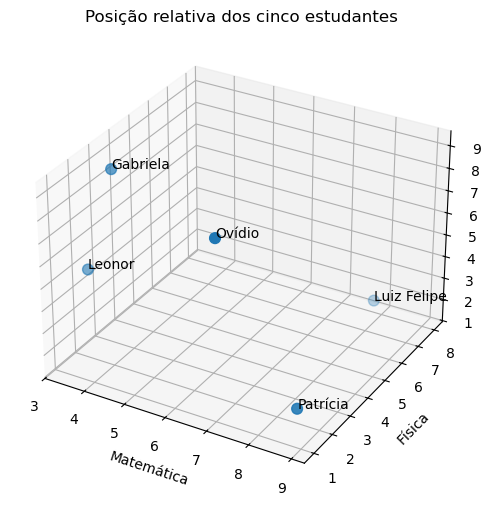

In [11]:
fig = plt.figure(figsize = (8, 6))
ax = fig.add_subplot(projection='3d')

ax.scatter(vestibular["matematica"], vestibular["fisica"], vestibular["quimica"], s=60)
for nome, linha in vestibular.iterrows():
    ax.text(linha["matematica"], linha["fisica"], linha["quimica"], nome)

ax.set_xlabel('Matemática')
ax.set_ylabel('Física')
ax.set_zlabel('Química')
ax.set_title('Posição relativa dos cinco estudantes')

# Exibir o gráfico
plt.show()

In [12]:
# Matriz de distâncias euclidianas D0
D0 = pd.DataFrame(squareform(pdist(vestibular, "euclidean")),
                  index=vestibular.index, columns=vestibular.index)
D0.round(3)

,Gabriela,Luiz Felipe,Patrícia,Ovídio,Leonor
Gabriela,0.000,10.132,8.420,3.713,4.170
Luiz Felipe,10.132,0.000,7.187,10.290,8.223
Patrícia,8.420,7.187,0.000,6.580,6.045
Ovídio,3.713,10.290,6.580,0.000,5.474
Leonor,4.170,8.223,6.045,5.474,0.000


Para enxergar cada estágio, vamos criar uma função que reproduz o esquema de aglomeração do livro: a cada passo ela calcula a distância entre os grupos pelo método escolhido (sempre a partir de $D_0$) e junta o par mais próximo.

In [13]:
def esquema_aglomeracao(D, metodo="unico"):

    nomes = list(D.index)
    grupos = [[nome] for nome in nomes]
    estagios = []

    # Critério de cada método de encadeamento
    criterio = {"unico": np.min, "completo": np.max, "medio": np.mean}[metodo]

    while len(grupos) > 1:
        melhor = None
        for i in range(len(grupos)):
            for j in range(i + 1, len(grupos)):
                d = criterio(D.loc[grupos[i], grupos[j]].values)
                if melhor is None or d < melhor[0]:
                    melhor = (d, i, j)

        d, i, j = melhor
        # O grupo maior aparece como "Agrupamento" e o menor como "Observação agrupada"
        a, b = sorted([grupos[i], grupos[j]], key=len, reverse=True)
        estagios.append([" - ".join(a), " - ".join(b), np.round(d, 3)])

        grupos = [g for k, g in enumerate(grupos) if k not in (i, j)] + [a + b]

    resultado = pd.DataFrame(estagios, columns=["Agrupamento", "Observação agrupada", "Distância"])
    resultado.index = range(1, len(resultado) + 1)
    resultado.index.name = "Estágio"

    return resultado

Para interpretar os dendrogramas e visualizar os agrupamentos, como nas Figuras 9.13 a 9.18 do livro, vamos criar duas funções gráficas: uma desenha linhas de corte (I, II, III ...) entre os estágios e mostra os saltos de distância, e a outra mostra os alunos em 3D coloridos pelo cluster.

In [14]:
def dendrograma_cortes(Z, rotulos, titulo):

    alturas = Z[:, 2]
    cortes = (alturas[:-1] + alturas[1:]) / 2  # Uma linha entre cada par de estágios
    romanos = ["I", "II", "III", "IV", "V", "VI", "VII", "VIII"]

    fig, ax = plt.subplots(figsize = (10, 5))
    dendrogram(Z, labels=rotulos, orientation="right", ax=ax)

    for i, corte in enumerate(cortes):
        ax.axvline(corte, color='red', linestyle='--', linewidth=1)
        ax.text(corte, ax.get_ylim()[1] * 0.97, f' {romanos[i]}', ha='left', va='top', color='red')

    ax.set_xlabel('Distância')
    ax.set_title(titulo)

    # Exibir o gráfico
    plt.show()

    # Saltos de distância entre estágios
    saltos = pd.DataFrame({"De": alturas[:-1], "Para": alturas[1:], "Salto": np.diff(alturas)},
                          index=[f"Estágio {i+1} -> {i+2}" for i in range(len(alturas) - 1)])
    return saltos.round(3)


def grafico_3d_clusters(dados, rotulos, titulo, ax=None, centroides=None):

    if ax is None:
        fig = plt.figure(figsize = (8, 6))
        ax = fig.add_subplot(projection='3d')

    ax.scatter(dados.iloc[:, 0], dados.iloc[:, 1], dados.iloc[:, 2], c=rotulos, cmap='tab10', s=80, vmin=0, vmax=9)
    for nome, linha in dados.iterrows():
        ax.text(linha.iloc[0], linha.iloc[1], linha.iloc[2], f'  {nome}', fontsize=9)

    if centroides is not None:
        ax.scatter(centroides.iloc[:, 0], centroides.iloc[:, 1], centroides.iloc[:, 2],
                   marker='X', s=200, color='black', label='Centroides')
        ax.legend()

    ax.set_xlabel('Matemática')
    ax.set_ylabel('Física')
    ax.set_zlabel('Química')
    ax.set_title(titulo)
    return ax

##### *Encadeamento único*

In [15]:
esquema_aglomeracao(D0, metodo="unico")

,Agrupamento,Observação agrupada,Distância
Estágio,,,
1,Gabriela,Ovídio,3.713
2,Gabriela - Ovídio,Leonor,4.170
3,Gabriela - Ovídio - Leonor,Patrícia,6.045
4,Gabriela - Ovídio - Leonor - Patrícia,Luiz Felipe,7.187


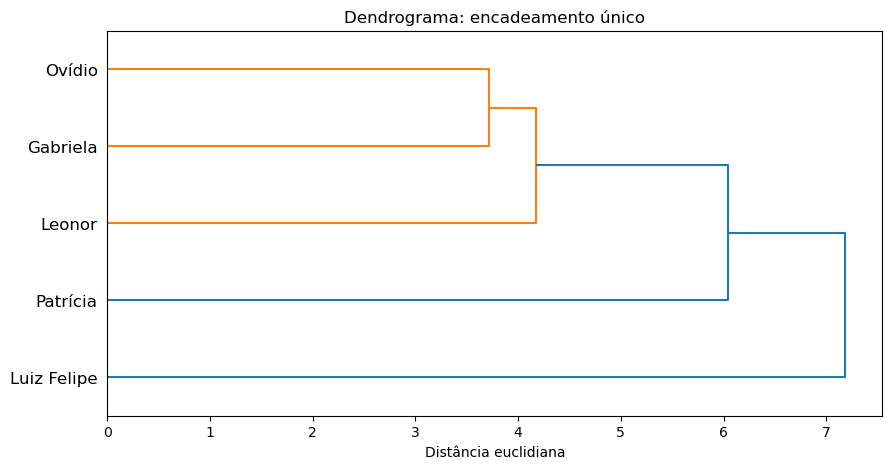

In [16]:
# Dendrograma (o scipy usa a mesma lógica)
encadeamento_unico = linkage(pdist(vestibular, "euclidean"), method="single")

fig, ax = plt.subplots(figsize = (10, 5))
dendrogram(encadeamento_unico, labels=vestibular.index.tolist(), orientation="right", ax=ax)
ax.set_xlabel('Distância euclidiana')
ax.set_title('Dendrograma: encadeamento único')

# Exibir o gráfico
plt.show()

Note que Gabriela e Ovídio se juntam primeiro (3.713), depois entram Leonor (4.170), Patrícia (6.045) e, por último, Luiz Felipe (7.187).

Para ler o dendrograma, olhamos os `saltos de distância` entre um estágio e outro. O maior salto (de 4.170 para 6.045) acontece quando Patrícia entra no grupo, sinal de que ela não é tão parecida com os demais. Um critério útil é ficar com a quantidade de grupos do estágio imediatamente anterior ao grande salto: aqui, `três clusters`, sendo Gabriela-Ovídio-Leonor, Patrícia e Luiz Felipe.

`OBS:` *Se os saltos forem muito pequenos, a distância quadrática euclidiana ajuda a deixá-los mais nítidos.*

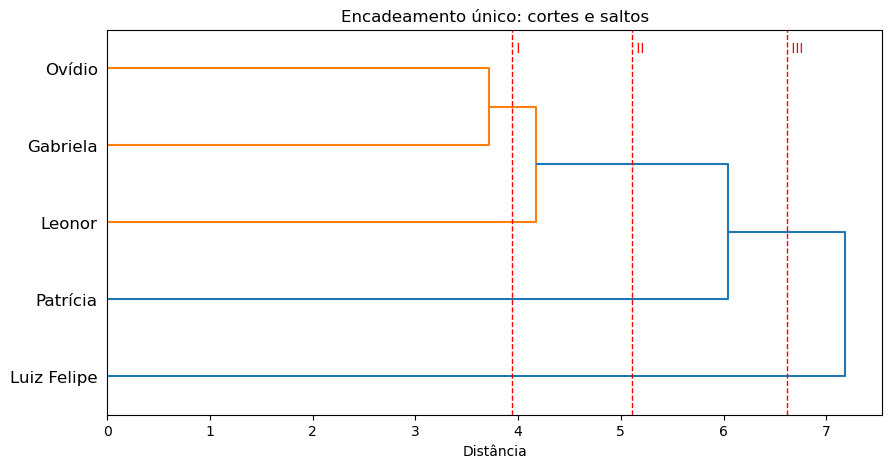

,De,Para,Salto
Estágio 1 -> 2,3.713,4.170,0.457
Estágio 2 -> 3,4.170,6.045,1.875
Estágio 3 -> 4,6.045,7.187,1.142


In [17]:
# Figuras 9.13 e 9.14: linhas de corte e saltos de distância
dendrograma_cortes(encadeamento_unico, vestibular.index.tolist(), 'Encadeamento único: cortes e saltos')

Note que a linha I corta o dendrograma em quatro clusters, a II em três e a III em dois. O maior salto (1.875) é a entrada de Patrícia, por isso ficamos com a solução da linha II.

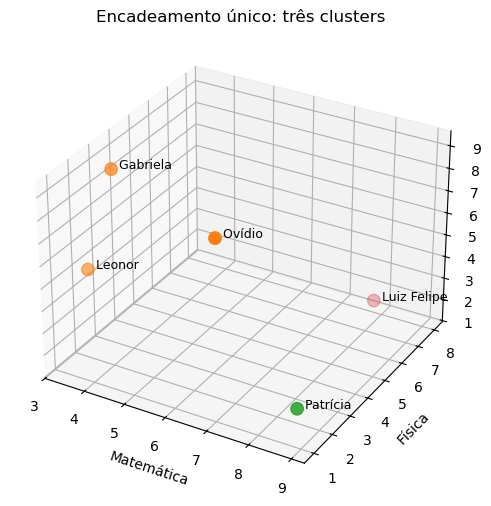

In [18]:
# Figura 9.15: agrupamentos sugeridos pelo encadeamento único (3 clusters)
grafico_3d_clusters(vestibular[["matematica", "fisica", "quimica"]],
                    fcluster(encadeamento_unico, t=3, criterion="maxclust"),
                    'Encadeamento único: três clusters')

# Exibir o gráfico
plt.show()

##### *Encadeamento completo*

In [19]:
esquema_aglomeracao(D0, metodo="completo")

,Agrupamento,Observação agrupada,Distância
Estágio,,,
1,Gabriela,Ovídio,3.713
2,Gabriela - Ovídio,Leonor,5.474
3,Luiz Felipe,Patrícia,7.187
4,Gabriela - Ovídio - Leonor,Luiz Felipe - Patrícia,10.290


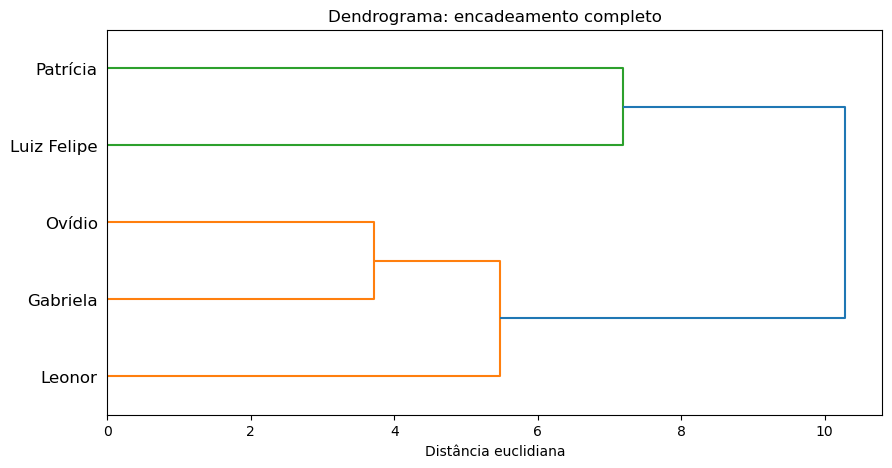

In [20]:
encadeamento_completo = linkage(pdist(vestibular, "euclidean"), method="complete")

fig, ax = plt.subplots(figsize = (10, 5))
dendrogram(encadeamento_completo, labels=vestibular.index.tolist(), orientation="right", ax=ax)
ax.set_xlabel('Distância euclidiana')
ax.set_title('Dendrograma: encadeamento completo')

# Exibir o gráfico
plt.show()

Note que no terceiro estágio a ordem muda: em vez de Patrícia entrar no primeiro grupo, ela se junta a Luiz Felipe (7.187). Com três grupos a solução é a mesma do encadeamento único, mas com dois grupos ela muda: Gabriela-Ovídio-Leonor de um lado e Luiz Felipe-Patrícia do outro.

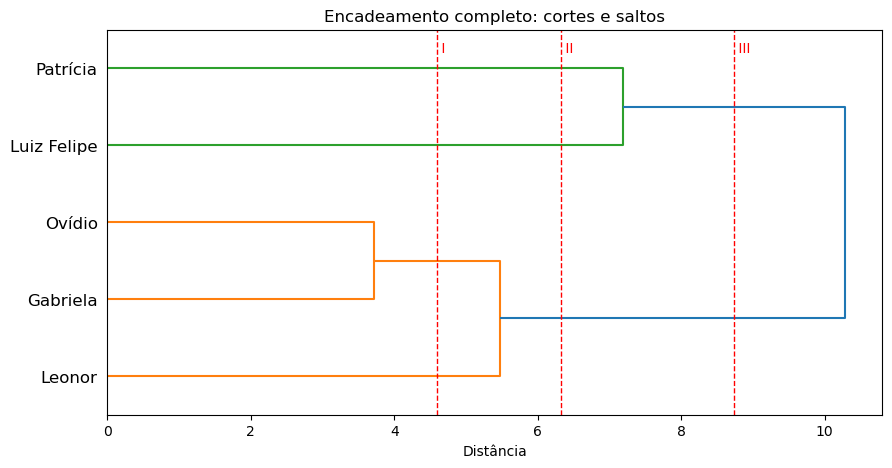

,De,Para,Salto
Estágio 1 -> 2,3.713,5.474,1.760
Estágio 2 -> 3,5.474,7.187,1.713
Estágio 3 -> 4,7.187,10.290,3.103


In [21]:
# Figura 9.17: linhas de corte e saltos de distância
dendrograma_cortes(encadeamento_completo, vestibular.index.tolist(), 'Encadeamento completo: cortes e saltos')

Note que no encadeamento completo o maior salto (3.103) é a fusão final dos dois grupos, por isso a solução com dois clusters (linha III) também é razoável aqui.

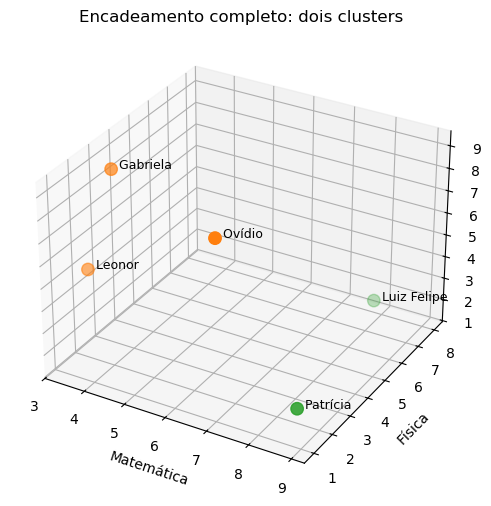

In [22]:
# Figura 9.18: agrupamentos sugeridos pelo encadeamento completo (2 clusters)
grafico_3d_clusters(vestibular[["matematica", "fisica", "quimica"]],
                    fcluster(encadeamento_completo, t=2, criterion="maxclust"),
                    'Encadeamento completo: dois clusters')

# Exibir o gráfico
plt.show()

##### *Encadeamento médio*

In [23]:
esquema_aglomeracao(D0, metodo="medio")

,Agrupamento,Observação agrupada,Distância
Estágio,,,
1,Gabriela,Ovídio,3.713
2,Gabriela - Ovídio,Leonor,4.822
3,Gabriela - Ovídio - Leonor,Patrícia,7.015
4,Gabriela - Ovídio - Leonor - Patrícia,Luiz Felipe,8.958


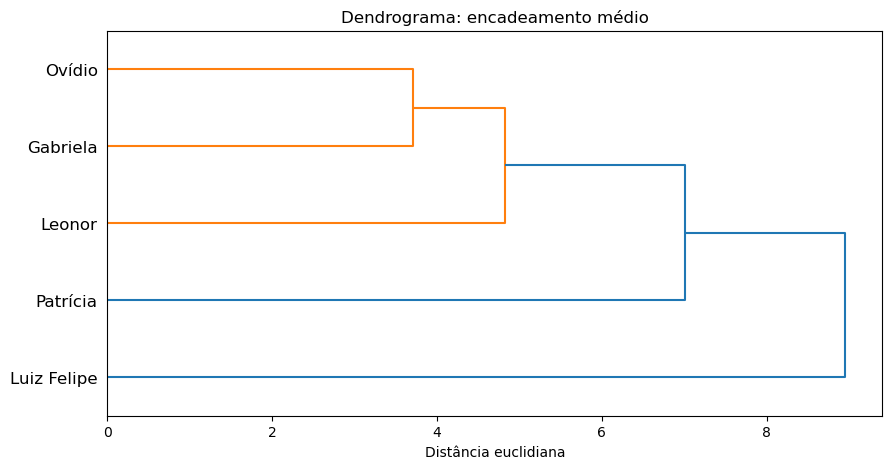

In [24]:
encadeamento_medio = linkage(pdist(vestibular, "euclidean"), method="average")

fig, ax = plt.subplots(figsize = (10, 5))
dendrogram(encadeamento_medio, labels=vestibular.index.tolist(), orientation="right", ax=ax)
ax.set_xlabel('Distância euclidiana')
ax.set_title('Dendrograma: encadeamento médio')

# Exibir o gráfico
plt.show()

Note que o encadeamento médio mantém a mesma ordem e a mesma alocação do encadeamento único, só com distâncias diferentes. Isso indica que as observações são bem distintas entre si. Se fossem parecidas, o médio concordaria com o completo.

`OBS:` *Por isso o livro recomenda aplicar os três métodos e comparar os dendrogramas antes de decidir a quantidade de grupos.*

In [25]:
# Alocação das observações em 3 clusters (cortando o dendrograma do encadeamento único)
vestibular["cluster_hierarquico"] = fcluster(encadeamento_unico, t=3, criterion="maxclust")
vestibular

,matematica,fisica,quimica,cluster_hierarquico
Gabriela,3.7,2.7,9.1,1
Luiz Felipe,7.8,8.0,1.5,3
Patrícia,8.9,1.0,2.7,2
Ovídio,7.0,1.0,9.0,1
Leonor,3.4,2.0,5.0,1


### **Escalonamento multidimensional**

A partir da matriz de distâncias, o `escalonamento multidimensional` (MDS) gera um gráfico em duas dimensões com as posições relativas das observações, qualquer que seja a quantidade de variáveis.

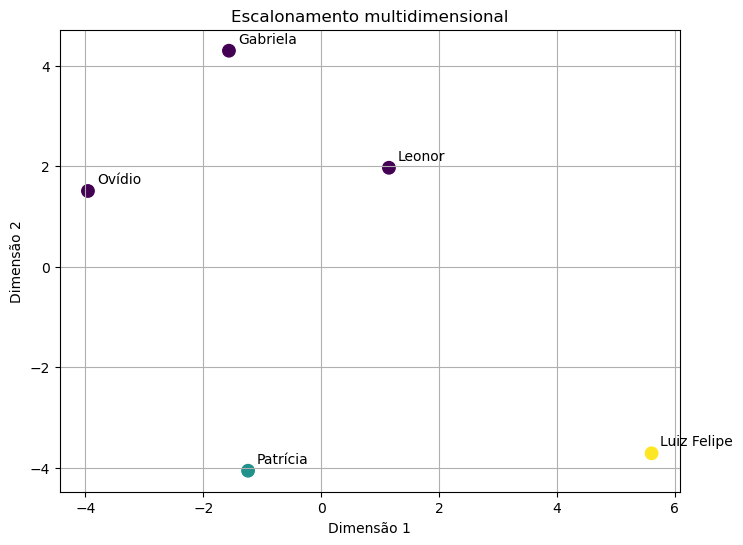

In [26]:
mds = MDS(n_components=2, dissimilarity="precomputed", random_state=42, n_init=4)
coordenadas = mds.fit_transform(D0.values)

fig, ax = plt.subplots(figsize = (8, 6))
ax.scatter(coordenadas[:, 0], coordenadas[:, 1], s=80, c=vestibular["cluster_hierarquico"], cmap="viridis")
for nome, (x, y) in zip(vestibular.index, coordenadas):
    ax.text(x + 0.15, y + 0.15, nome)

ax.set_xlabel('Dimensão 1')
ax.set_ylabel('Dimensão 2')
ax.set_title('Escalonamento multidimensional')
plt.grid(True)

# Exibir o gráfico
plt.show()

### **Esquema não hierárquico k-means**

A quantidade de clusters $K$ é definida antes, por um critério do pesquisador ou pelo resultado de um esquema hierárquico.

Procedimento (Johnson e Wichern, 2007):
1. Alocar as observações arbitrariamente nos $K$ clusters e calcular os centroides.
2. Escolher uma observação e realocá-la no cluster de centroide mais próximo. Os centroides do cluster que recebe e do que perde a observação são recalculados.
3. Repetir até que nenhuma observação possa ser realocada.

Quando a observação $p$ entra ou sai de um cluster com $N$ observações e centroide $\overline{x}$:

$\overline{x}_{novo} = \frac{N\cdot\overline{x} + x_p}{N + 1}$ (inclusão) e $\overline{x}_{novo} = \frac{N\cdot\overline{x} - x_p}{N - 1}$ (exclusão)

`OBS:` *Como não é preciso recalcular a matriz de distâncias a cada passo, o k-means funciona bem em bases muito maiores que as dos métodos hierárquicos. As variáveis também precisam ser padronizadas se estiverem em unidades diferentes.*

In [27]:
def kmeans_realocacao(dados, alocacao_inicial, historico=None):

    X = dados.values
    nomes = list(dados.index)
    rotulos = np.array(alocacao_inicial)
    houve_mudanca = True

    if historico is not None:
        historico.append(rotulos.copy())

    while houve_mudanca:
        houve_mudanca = False
        for p in range(len(X)):
            atual = rotulos[p]
            if np.sum(rotulos == atual) == 1:
                continue  # Não esvaziar um cluster

            # Distância de p ao centroide de cada cluster, supondo p dentro dele
            distancias = {}
            for c in np.unique(rotulos):
                membros = (rotulos == c)
                membros[p] = True
                centroide = X[membros].mean(axis=0)
                distancias[c] = np.sqrt(np.sum((X[p] - centroide)**2))

            melhor = min(distancias, key=distancias.get)
            if melhor != atual:
                print(f"{nomes[p]} sai do cluster {atual} e vai para o cluster {melhor} (distância {np.round(distancias[melhor], 3)})")
                rotulos[p] = melhor
                houve_mudanca = True
                if historico is not None:
                    historico.append(rotulos.copy())

    return rotulos

#### Exemplo: k-means com K = 3

Partimos da alocação arbitrária do livro: Gabriela e Luiz Felipe no cluster 1, Patrícia e Ovídio no cluster 2 e Leonor no cluster 3.

In [28]:
notas = vestibular[["matematica", "fisica", "quimica"]]

# Gabriela, Luiz Felipe, Patrícia, Ovídio, Leonor
alocacao_inicial = [1, 1, 2, 2, 3]

passos_kmeans = []
vestibular["cluster_kmeans"] = kmeans_realocacao(notas, alocacao_inicial, historico=passos_kmeans)
vestibular

Gabriela sai do cluster 1 e vai para o cluster 3 (distância 2.085)
Ovídio sai do cluster 2 e vai para o cluster 3 (distância 2.791)


,matematica,fisica,quimica,cluster_hierarquico,cluster_kmeans
Gabriela,3.7,2.7,9.1,1,3
Luiz Felipe,7.8,8.0,1.5,3,1
Patrícia,8.9,1.0,2.7,2,2
Ovídio,7.0,1.0,9.0,1,3
Leonor,3.4,2.0,5.0,1,3


In [29]:
# Centroides finais
centroides = notas.groupby(vestibular["cluster_kmeans"]).mean()
centroides.round(2)

,matematica,fisica,quimica
cluster_kmeans,,,
1,7.8,8.0,1.5
2,8.9,1.0,2.7
3,4.7,1.9,7.7


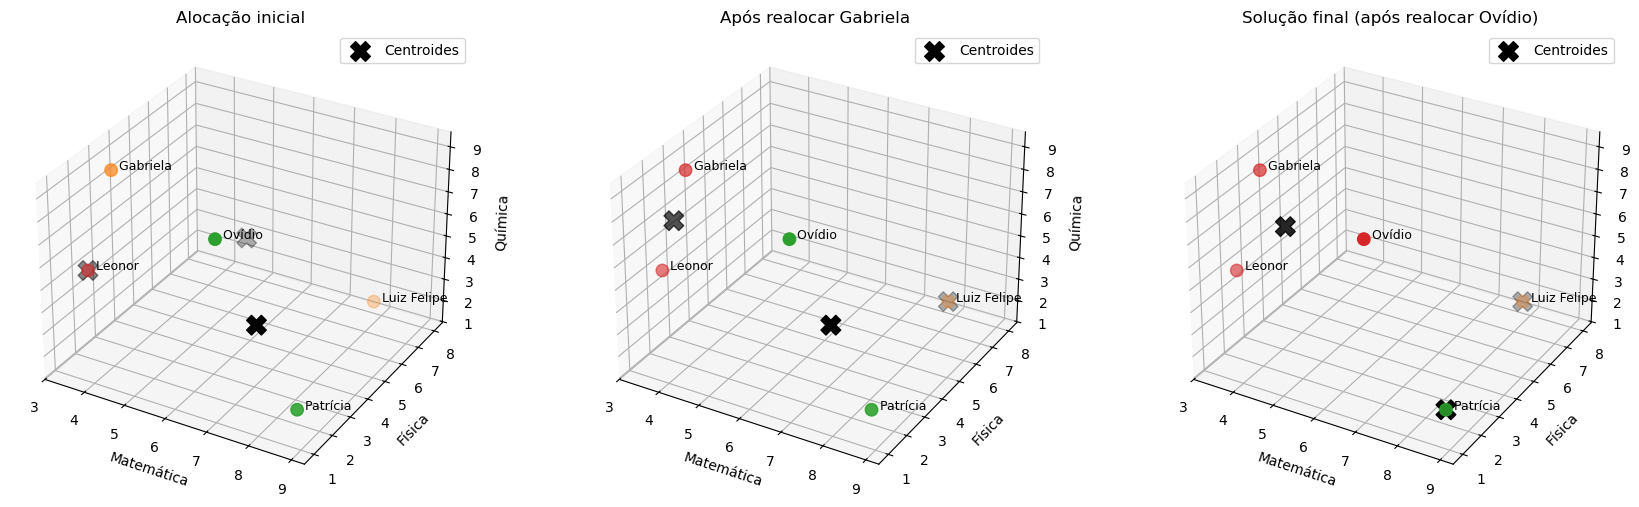

In [30]:
# Figuras 9.21 a 9.23: alocação inicial, realocação de Gabriela e solução final
fig = plt.figure(figsize = (21, 6))
titulos = ['Alocação inicial', 'Após realocar Gabriela', 'Solução final (após realocar Ovídio)']

for i, (rotulos, titulo) in enumerate(zip(passos_kmeans, titulos)):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    centroides_passo = notas.groupby(rotulos).mean()
    grafico_3d_clusters(notas, rotulos, titulo, ax=ax, centroides=centroides_passo)

# Exibir o gráfico
plt.show()

In [31]:
# Distâncias euclidianas entre cada observação e cada centroide
pd.DataFrame(cdist(notas, centroides), index=notas.index,
             columns=[f"Cluster {c}" for c in centroides.index]).round(3)

,Cluster 1,Cluster 2,Cluster 3
Gabriela,10.132,8.420,1.897
Luiz Felipe,0.000,7.187,9.234
Patrícia,7.187,0.000,6.592
Ovídio,10.290,6.580,2.791
Leonor,8.223,6.045,2.998


Note que Gabriela e Ovídio foram realocados para o grupo de Leonor, e a solução final tem os mesmos três grupos dos encadeamentos único e médio: Gabriela-Ovídio-Leonor, Luiz Felipe e Patrícia.

In [32]:
# Conferindo com o KMeans do sklearn (várias inicializações aleatórias)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42).fit(notas)
pd.crosstab(vestibular["cluster_kmeans"], kmeans.labels_, rownames=["Realocação"], colnames=["sklearn"])

c:\Users\jv_at\anaconda3\envs\bmte\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


sklearn,0,1,2
Realocação,,,
1,0,0,1
2,0,1,0
3,3,0,0


`OBS:` *O sklearn numera os clusters de outro jeito, mas a tabela cruzada mostra que a partição é a mesma. Reaplicar o k-means com várias alocações iniciais (o parâmetro `n_init`) ajuda a avaliar a estabilidade da solução.*

#### **ANOVA para cada variável**

Depois do agrupamento verificamos, com a ANOVA de um fator (capítulo 7), se cada variável tem médias diferentes entre os clusters:

$H_0:$ a variável tem a mesma média em todos os grupos

$H_1:$ a variável tem média diferente em pelo menos um grupo

$F = \frac{\sum_{k=1}^{K}N_k\cdot(\overline{X}_k - \overline{X})^2/(K-1)}{\sum_{k=1}^{K}\sum_{i}(X_{ki} - \overline{X}_k)^2/(n-K)}$

As variáveis com maior $F$ são as que mais contribuem para a formação dos grupos.

In [33]:
anova_clusters = []
for variavel in notas.columns:
    grupos = [notas.loc[vestibular["cluster_kmeans"] == c, variavel] for c in sorted(vestibular["cluster_kmeans"].unique())]
    f_cal, p_valor = stats.f_oneway(*grupos)
    anova_clusters.append([variavel, f_cal, p_valor])

anova_clusters = pd.DataFrame(anova_clusters, columns=["Variável", "F", "Sig. F"]).set_index("Variável")
print(f"F crítico (5%; 2 e 2 gl): {np.round(stats.f.ppf(0.95, 2, 2), 2)}")
anova_clusters.round(3)

F crítico (5%; 2 e 2 gl): 19.0


,F,Sig. F
Variável,,
matematica,2.079,0.325
fisica,22.337,0.043
quimica,3.506,0.222


Note que apenas a nota de física tem média diferente entre os grupos (F = 22.337 > 19.00, Sig. F = 0.043). Matemática (Sig. F = 0.325) e química (Sig. F = 0.222) não diferem significativamente, muito por causa da amostra pequena (só cinco alunos).

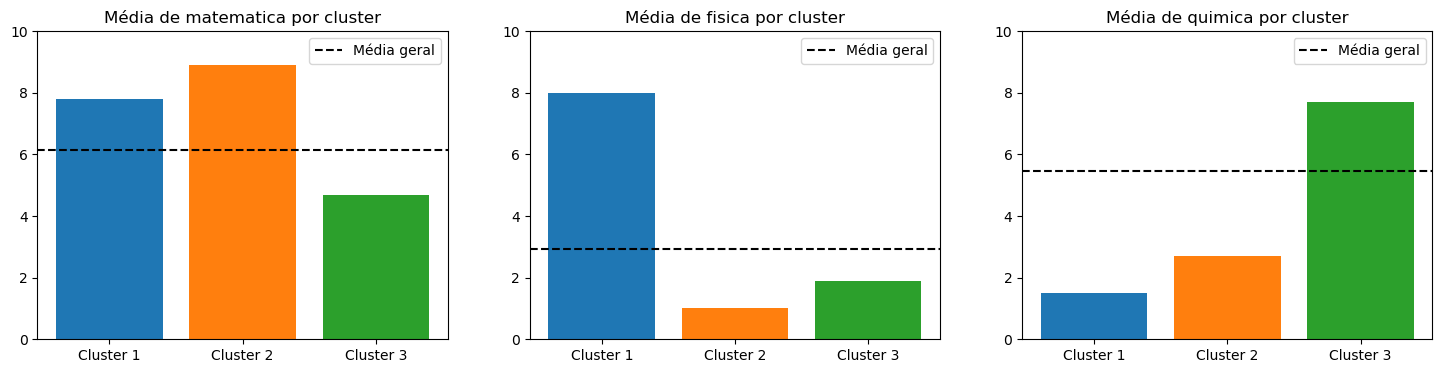

In [34]:
# Figuras 9.43 a 9.45: médias de cada variável nos três clusters
medias_cluster = notas.groupby(vestibular["cluster_kmeans"]).mean()

fig, ax = plt.subplots(1, 3, figsize = (18, 4))
for eixo, variavel in zip(ax, notas.columns):
    eixo.bar([f"Cluster {c}" for c in medias_cluster.index], medias_cluster[variavel], color=['C0', 'C1', 'C2'])
    eixo.axhline(notas[variavel].mean(), color='black', linestyle='--', label='Média geral')
    eixo.set_title(f'Média de {variavel} por cluster')
    eixo.set_ylim(0, 10)
    eixo.legend()

# Exibir o gráfico
plt.show()

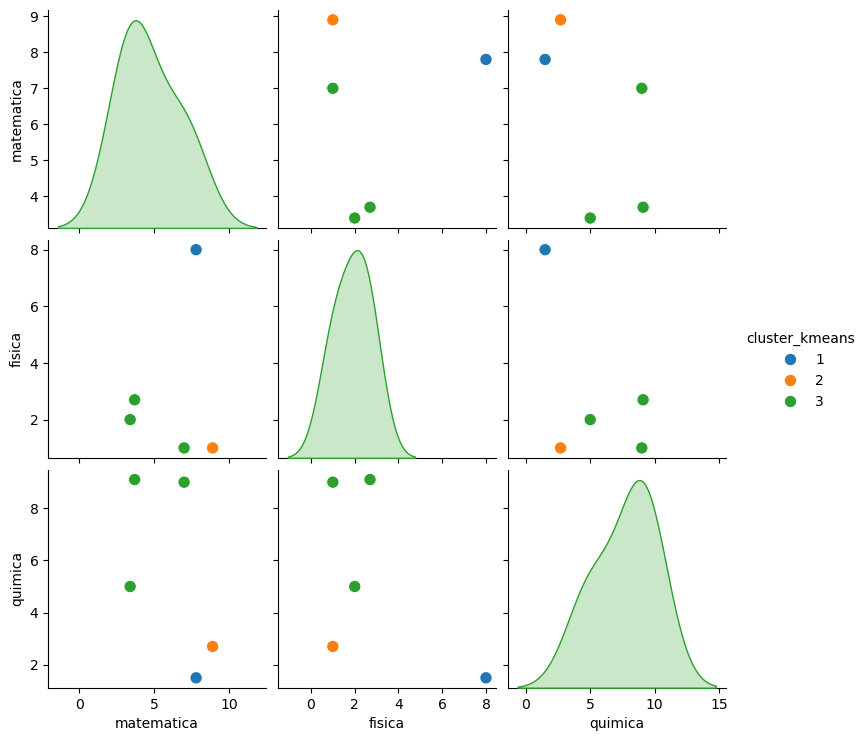

In [35]:
# Figura 9.75: inter-relação das variáveis e posição das observações de cada cluster
sns.pairplot(vestibular[["matematica", "fisica", "quimica", "cluster_kmeans"]],
             hue="cluster_kmeans", palette="tab10", plot_kws={"s": 80});

`OBS:` *Se uma variável não contribui para a formação dos grupos, o livro recomenda refazer a análise sem ela. A variável de cluster também pode ser usada depois em outras técnicas, como análise de correspondência ou regressão logística multinomial.*

## **Apêndice: Detecção de Outliers Multivariados**

Como os agrupamentos são sensíveis a outliers, vale identificá-los antes. O livro apresenta o algoritmo `BACON` (*Blocked Adaptive Computationally Efficient Outlier Nominators*), de Billor, Hadi e Velleman (2000), baseado na `distância de Mahalanobis`, que não depende das unidades de medida das variáveis:

$d_i = \sqrt{(x_i - \overline{x})^T\cdot S^{-1}\cdot(x_i - \overline{x})}$

sendo $S$ a matriz de covariâncias.

Procedimento:
1. Escolher as $m$ observações ($m = 4\cdot k$, ou um pouco mais se houver valores repetidos) com menor distância de Mahalanobis em relação à amostra toda. Elas formam o grupo básico $M$.
2. Calcular a distância de cada observação à média do grupo $M$, usando a covariância de $M$.
3. Colocar em $M$ todas as observações com distância abaixo de um limiar baseado na distribuição $\chi^2$ (com $\alpha = 0.15$, o padrão do Stata), corrigido pelo tamanho da amostra.
4. Repetir os passos 2 e 3 até $M$ não mudar. Quem ficou de fora é outlier.

In [36]:
def bacon(dados, alpha=0.15):

    X = np.asarray(dados, dtype=float)
    n, k = X.shape

    def mahalanobis(X, media, cov):
        diferenca = X - media
        return np.sqrt(np.einsum('ij,jk,ik->i', diferenca, np.linalg.pinv(cov), diferenca))

    # Passo 1: grupo básico inicial com as m menores distâncias
    d = mahalanobis(X, X.mean(axis=0), np.cov(X, rowvar=False))
    ordem = np.argsort(d)
    m = 4 * k
    # Se houver valores repetidos, aumentamos m até a covariância poder ser invertida
    while np.linalg.matrix_rank(np.cov(X[ordem[:m]], rowvar=False)) < k:
        m += k
    basico = ordem[:m]

    while True:
        # Passo 2: distâncias em relação ao grupo básico
        subamostra = X[basico]
        r = len(basico)
        d = mahalanobis(X, subamostra.mean(axis=0), np.cov(subamostra, rowvar=False))

        # Passo 3: limiar qui-quadrado com fator de correção
        h = (n + k + 1) // 2
        c_np = 1 + (k + 1) / (n - k) + 2 / (n - 1 - 3 * k)
        c_hr = max(0, (h - r) / (h + r))
        limiar = (c_np + c_hr) * np.sqrt(chi2.ppf(1 - alpha / n, k))
        novo = np.where(d < limiar)[0]

        # Passo 4: parar quando o grupo básico não muda
        if set(novo) == set(basico):
            break
        basico = novo

    outlier = np.ones(n, dtype=int)
    outlier[basico] = 0

    return outlier

#### Exemplo com dados simulados

O livro usa a base `Bacon.dta`, com renda, idade e tempo de formado de 20.000 engenheiros, que não acompanha este repositório. Para mostrar o algoritmo, vamos simular uma base parecida e inserir nela os quatro outliers encontrados no livro.

In [37]:
np.random.seed(42)
n = 20000

# Simulando engenheiros: renda cresce com o tempo de formado
idade = np.random.randint(23, 61, n)
tformado = np.clip(idade - np.random.randint(21, 31, n), 0, None)  # Formados entre 21 e 30 anos
renda = np.clip(4000 + 280 * tformado + np.random.normal(0, 1200, n), 1000, None)

engenheiros = pd.DataFrame({"renda": renda.round(2), "idade": idade, "tformado": tformado})

# Inserindo os quatro outliers do livro
outliers_livro = pd.DataFrame({"renda": [30869.93, 34773.54, 41191.15, 32924.19],
                               "idade": [30, 42, 50, 31],
                               "tformado": [15, 17, 21, 16]})
engenheiros = pd.concat([engenheiros, outliers_livro], ignore_index=True)

engenheiros.describe().round(2)

,renda,idade,tformado
count,20004.00,20004.00,20004.00
mean,8533.81,41.46,16.15
std,3309.56,10.89,10.89
min,1000.00,23.00,0.00
25%,5868.05,32.00,7.00
50%,8477.47,41.00,16.00
75%,11139.71,51.00,25.00
max,41191.15,60.00,39.00


In [38]:
engenheiros["outbacon"] = bacon(engenheiros[["renda", "idade", "tformado"]])

print(f"Total de observações: {len(engenheiros)}")
print(f"Outliers BACON: {engenheiros['outbacon'].sum()}")
engenheiros[engenheiros["outbacon"] == 1]

Total de observações: 20004
Outliers BACON: 4


,renda,idade,tformado,outbacon
20000,30869.93,30,15,1
20001,34773.54,42,17,1
20002,41191.15,50,21,1
20003,32924.19,31,16,1


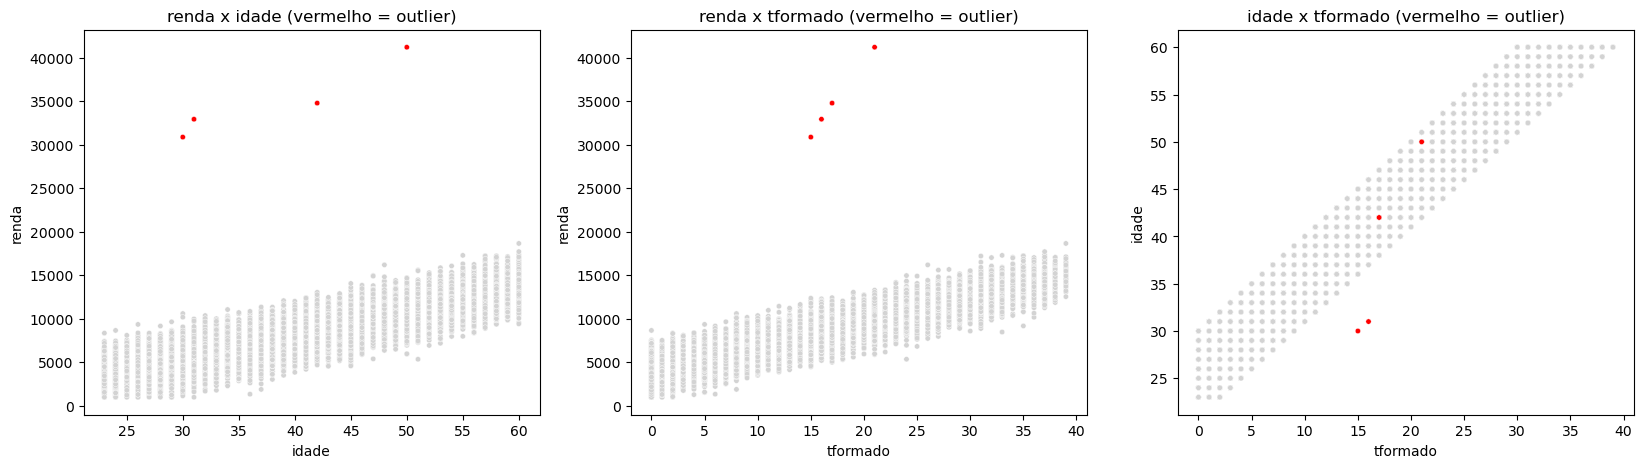

In [39]:
fig, ax = plt.subplots(1, 3, figsize = (20, 5))

pares_variaveis = [("idade", "renda"), ("tformado", "renda"), ("tformado", "idade")]
for eixo, (x, y) in zip(ax, pares_variaveis):
    sns.scatterplot(data=engenheiros, x=x, y=y, hue="outbacon", palette={0: "lightgray", 1: "red"},
                    s=15, ax=eixo, legend=False)
    eixo.set_title(f'{y} x {x} (vermelho = outlier)')

# Exibir o gráfico
plt.show()

Note que, entre as 20.004 observações, o BACON identificou exatamente os quatro engenheiros inseridos, os mesmos que o comando `bacon` do Stata encontra no livro. Eles têm renda muito acima do esperado para a idade e o tempo de formado, o que aparece com clareza nos gráficos de renda.

`OBS:` *O que fazer com os outliers é decisão do pesquisador: podem ser excluídos da análise, mas entender por que são discrepantes também pode render boas descobertas.*

## **Exercícios Análise de Agrupamentos**

Os exercícios do capítulo 9 do livro usam bases que acompanham a obra e não estão neste repositório:

1. `Bolsa de Estudo.dta`: agrupar 100 estudantes por idade e renda (encadeamento completo, distância quadrática euclidiana, com padronização Zscores) e investigar outliers.
2. `Regional Varejista.dta`: agrupar 18 lojas por atendimento, sortimento e organização (encadeamento único, k-means, ANOVA e escalonamento multidimensional).
3. `Pesquisa Binária.dta`: agrupar 35 empresas a partir de 50 respostas binárias (encadeamento médio e emparelhamento simples).
4. `Hortifrúti.dta`: agrupar 16 semanas de vendas de banana, laranja e maçã pela correlação de Pearson entre as linhas.

`OBS:` *Para resolvê-los, coloque as bases na pasta `dados/` e aplique as mesmas funções deste notebook (`esquema_aglomeracao`, `linkage`, `KMeans`, `MDS` e `bacon`).*